In [1]:
import torch
import torch.nn as nn
import yfinance as yf
from tqdm import tqdm
from torch.utils.data import DataLoader, Dataset
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
import numpy as np
from sklearn.metrics import f1_score

In [2]:
# hyperparameters
train_test_prop = 0.8
batch_size = 16 # how many independent sequences will we process in parallel?
block_size = 8 # the temporal block size of the model
max_iters = 50
learning_rate = 3e-4
scheduler_step_size = 40
scheduler_gamma = 0.5
device = 'cuda' if torch.cuda.is_available() else 'cpu'
show_stats = True

# model parameters
n_hidden = 128
n_layer = 2
dropout = 0.2
is_lstm = True

torch.manual_seed(1337)

In [3]:
data = yf.download("AMZN")
data.columns = data.columns.droplevel(1)
data = data["2020-01-01":]


[*********************100%***********************]  1 of 1 completed


In [4]:
data["1D Return"] = data["Close"].pct_change(1)
data["5D Return"] = data["Close"].pct_change(5)
data["20D Return"] = data["Close"].pct_change(20)
data["80D Return"] = data["Close"].pct_change(80)
data["120D Return"] = data["Close"].pct_change(120)
data["160D Return"] = data["Close"].pct_change(160)
data["200D Return"] = data["Close"].pct_change(200)
data["20D EMA"] = data["Close"].ewm(span=20, adjust=False).mean()
data["80D EMA"] = data["Close"].ewm(span=80, adjust=False).mean()
data["120D EMA"] = data["Close"].ewm(span=120, adjust=False).mean()
data["160D EMA"] = data["Close"].ewm(span=160, adjust=False).mean()
data["200D EMA"] = data["Close"].ewm(span=200, adjust=False).mean()
data.dropna(inplace=True)
data

Price,Adj Close,Close,High,Low,Open,Volume,1D Return,5D Return,20D Return,80D Return,120D Return,160D Return,200D Return,20D EMA,80D EMA,120D EMA,160D EMA,200D EMA
Date,,,,,,,,,,,,,,,,,,
2020-10-16,163.635498,163.635498,169.983002,158.000000,168.161499,129488000,-0.019750,-0.004241,0.107550,0.196866,0.414260,0.674920,0.724285,162.155254,153.740987,146.638413,140.434857,135.321374
2020-10-19,160.360504,160.360504,166.449997,159.636993,164.980499,104472000,-0.020014,-0.068465,0.083345,0.164319,0.351708,0.680056,0.710539,161.984326,153.904432,146.865224,140.682381,135.570519
2020-10-20,160.850494,160.850494,163.300003,159.600494,161.113998,90194000,0.003056,-0.065809,0.028130,0.194640,0.300327,0.628182,0.690601,161.876342,154.075940,147.096386,140.932917,135.822061
2020-10-21,159.246994,159.246994,161.694000,158.000000,160.625000,91854000,-0.009969,-0.053147,0.061696,0.188242,0.393213,0.655348,0.670254,161.625928,154.203620,147.297222,141.160421,136.055145
2020-10-22,158.820007,158.820007,159.937500,156.097000,159.493500,84240000,-0.002681,-0.048597,0.051861,0.151362,0.371509,0.670831,0.678885,161.358697,154.317605,147.487681,141.379794,136.281661
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-12-20,224.919998,224.919998,226.210007,218.729996,219.839996,88279200,0.007300,-0.011167,0.133784,0.316862,0.124600,0.207884,0.272028,220.113396,202.257927,196.341309,191.527284,187.144642
2024-12-23,225.059998,225.059998,226.880005,223.899994,225.009995,28070000,0.000622,-0.033787,0.141741,0.307576,0.139025,0.192687,0.283490,220.584501,202.820941,196.815998,191.943839,187.521909
2024-12-24,229.050003,229.050003,229.139999,226.130005,226.940002,15007500,0.017729,-0.009085,0.137007,0.283193,0.145250,0.213446,0.331996,221.390739,203.468572,197.348791,192.404785,187.935124


In [5]:
data.drop(columns=["Close", "Adj Close", "Open", "High", "Low", "Volume"], inplace=True)
data

Price,1D Return,5D Return,20D Return,80D Return,120D Return,160D Return,200D Return,20D EMA,80D EMA,120D EMA,160D EMA,200D EMA
Date,,,,,,,,,,,,
2020-10-16,-0.019750,-0.004241,0.107550,0.196866,0.414260,0.674920,0.724285,162.155254,153.740987,146.638413,140.434857,135.321374
2020-10-19,-0.020014,-0.068465,0.083345,0.164319,0.351708,0.680056,0.710539,161.984326,153.904432,146.865224,140.682381,135.570519
2020-10-20,0.003056,-0.065809,0.028130,0.194640,0.300327,0.628182,0.690601,161.876342,154.075940,147.096386,140.932917,135.822061
2020-10-21,-0.009969,-0.053147,0.061696,0.188242,0.393213,0.655348,0.670254,161.625928,154.203620,147.297222,141.160421,136.055145
2020-10-22,-0.002681,-0.048597,0.051861,0.151362,0.371509,0.670831,0.678885,161.358697,154.317605,147.487681,141.379794,136.281661
...,...,...,...,...,...,...,...,...,...,...,...,...
2024-12-20,0.007300,-0.011167,0.133784,0.316862,0.124600,0.207884,0.272028,220.113396,202.257927,196.341309,191.527284,187.144642
2024-12-23,0.000622,-0.033787,0.141741,0.307576,0.139025,0.192687,0.283490,220.584501,202.820941,196.815998,191.943839,187.521909
2024-12-24,0.017729,-0.009085,0.137007,0.283193,0.145250,0.213446,0.331996,221.390739,203.468572,197.348791,192.404785,187.935124


In [6]:
split_index = int(data.shape[0] * train_test_prop)
train_x = data.iloc[:split_index]
test_x = data.iloc[split_index:]
train_y = train_x["1D Return"].shift(-1).dropna()
test_y = test_x["1D Return"].shift(-1).dropna()
train_x = train_x.loc[train_y.index]
test_x = test_x.loc[test_y.index]
assert train_x.index.equals(train_y.index)
assert test_x.index.equals(test_y.index)

train_x.shape, train_y.shape, test_x.shape, test_y.shape

((843, 12), (843,), (211, 12), (211,))

In [7]:
scaler = StandardScaler()
scaler.fit(train_x)
train_x = scaler.transform(train_x)
test_x = scaler.transform(test_x)

In [8]:

class TimeSeriesDataset(Dataset):
    def __init__(self, x, y, block_size):
        self.x = x
        self.y = y
        self.block_size = block_size

    def __len__(self):
        return self.x.shape[0] - self.block_size

    def __getitem__(self, idx):
        return (
            torch.tensor(self.x[idx:idx+self.block_size], dtype=torch.float32),
            torch.tensor(self.y[idx], dtype=torch.float32)
        )


In [9]:
train_x = torch.tensor(train_x, dtype=torch.float32).to(device)
train_y = torch.tensor(train_y.values, dtype=torch.float32).unsqueeze(1).to(device)

train_dataset = TimeSeriesDataset(train_x, train_y, block_size)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

test_x = torch.tensor(test_x, dtype=torch.float32).to(device)
test_y = torch.tensor(test_y.values, dtype=torch.float32).unsqueeze(1).to(device)

test_dataset = TimeSeriesDataset(test_x, test_y, block_size)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

In [10]:
for i, j in train_loader:
    print(i.shape, j.shape)


torch.Size([16, 8, 12]) torch.Size([16, 1])
torch.Size([16, 8, 12]) torch.Size([16, 1])
torch.Size([16, 8, 12]) torch.Size([16, 1])
torch.Size([16, 8, 12]) torch.Size([16, 1])
torch.Size([16, 8, 12]) torch.Size([16, 1])
torch.Size([16, 8, 12]) torch.Size([16, 1])
torch.Size([16, 8, 12]) torch.Size([16, 1])
torch.Size([16, 8, 12]) torch.Size([16, 1])
torch.Size([16, 8, 12]) torch.Size([16, 1])
torch.Size([16, 8, 12]) torch.Size([16, 1])
torch.Size([16, 8, 12]) torch.Size([16, 1])
torch.Size([16, 8, 12]) torch.Size([16, 1])
torch.Size([16, 8, 12]) torch.Size([16, 1])
torch.Size([16, 8, 12]) torch.Size([16, 1])
torch.Size([16, 8, 12]) torch.Size([16, 1])
torch.Size([16, 8, 12]) torch.Size([16, 1])
torch.Size([16, 8, 12]) torch.Size([16, 1])
torch.Size([16, 8, 12]) torch.Size([16, 1])
torch.Size([16, 8, 12]) torch.Size([16, 1])
torch.Size([16, 8, 12]) torch.Size([16, 1])
torch.Size([16, 8, 12]) torch.Size([16, 1])
torch.Size([16, 8, 12]) torch.Size([16, 1])
torch.Size([16, 8, 12]) torch.Si

C:\Users\luis\AppData\Local\Temp\ipykernel_23924\612109033.py:12: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(self.x[idx:idx+self.block_size], dtype=torch.float32),
C:\Users\luis\AppData\Local\Temp\ipykernel_23924\612109033.py:13: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(self.y[idx], dtype=torch.float32)


In [11]:
class LSTMModel(nn.Module):
    def __init__(self, input_size: int, hidden_size: int, num_layers: int, output_size: int, dropout: float):
        super(LSTMModel, self).__init__()
        # self.net = nn.Sequential(
        #     nn.Linear(input_size, hidden_size),
        #     nn.ReLU(),
        #     nn.LSTM(hidden_size, hidden_size, num_layers, batch_first=True, dropout=dropout),
        #     nn.Linear(hidden_size, output_size)
        # )
        self.linear = nn.Linear(input_size, hidden_size)
        self.relu = nn.ReLU()
        if is_lstm:
            self.lstm = nn.LSTM(hidden_size, hidden_size, num_layers, batch_first=True, dropout=dropout)
        self.output = nn.Linear(hidden_size, output_size)
        # self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                torch.nn.init.zeros_(module.bias)
        elif isinstance(module, nn.LSTM):
            for name, param in module.named_parameters():
                if 'bias' in name:
                    nn.init.constant_(param, 0.0)
                elif 'weight_ih' in name:
                    nn.init.kaiming_normal_(param)
                elif 'weight_hh' in name:
                    nn.init.orthogonal_(param)
    
    def forward(self, idx):
        # idx: (batch_size, block_size, input_size) i.e. B x T x C
        x = self.linear(idx)
        x = self.relu(x)
        if is_lstm:
            x, _ = self.lstm(x)
            x = x[:, -1, :]
        x = self.output(x)
        return x
    

In [12]:

def run_epoch(model, criterion, optimizer, scheduler, dataloader, is_training=False, show_stats=False):
    epoch_loss = 0
    if is_training:
        model.train()
    else:
        model.eval()
    for idx, (x, y) in enumerate(dataloader):
        if is_training:
            optimizer.zero_grad()

        batchsize = x.shape[0]


        x = x.to(device)
        y = y.to(device)
                
        out = model(x)
        loss = criterion(out, y)

        if is_training:
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            scheduler.step()

        
        epoch_loss += (loss.detach().item()) / batchsize

    lr = scheduler.get_last_lr()[0]

    return epoch_loss, lr


In [13]:
# test_model = LSTMModel(input_size=train_x.shape[1], hidden_size=n_hidden, num_layers=n_layer, output_size=1, dropout=dropout).to(device)
# test_criterion = nn.MSELoss()
# test_optimizer = torch.optim.Adam(test_model.parameters(), lr=learning_rate)
# test_scheduler = torch.optim.lr_scheduler.StepLR(test_optimizer, step_size=scheduler_step_size, gamma=scheduler_gamma)

# run_epoch(test_model, test_criterion, test_optimizer, test_scheduler, train_loader, is_training=False)


In [14]:
model = LSTMModel(input_size=train_x.shape[1], hidden_size=n_hidden, num_layers=n_layer, output_size=1, dropout=0.2).to(device)

criterion = nn.MSELoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=scheduler_step_size, gamma=scheduler_gamma)
if show_stats:
    train_losses = np.empty(0)
    test_losses = np.empty(0)
    e_train_outs = np.empty(0)
    e_train_targets = np.empty(0)
    e_test_outs = np.empty(0)
    e_test_targets = np.empty(0)
    e_mses = []
    e_f1s = []

for epoch in tqdm(range(max_iters)):
    
    loss_train, lr_train = run_epoch(model, criterion, optimizer, scheduler, train_loader, is_training=True)
    loss_val, lr_val = run_epoch(model, criterion, optimizer, scheduler, test_loader, is_training=False)

    if show_stats:        
        with torch.no_grad():
            model.eval()
            for x, y in train_loader:
                y_pred = model(x.to(device)).detach().cpu().numpy()
                y_true = y.cpu().numpy()
                e_train_outs = np.append(e_train_outs, y_pred)
                e_train_targets = np.append(e_train_targets, y_true)



            for x, y in test_loader:
                y_pred = model(x.to(device)).detach().cpu().numpy()
                y_true = y.cpu().numpy()
                e_test_outs = np.append(e_test_outs, y_pred)
                e_test_targets = np.append(e_test_targets, y_true)
            
            e_mses.append((np.mean((e_train_outs - e_train_targets) ** 2), np.mean((e_test_outs - e_test_targets) ** 2)))
            e_f1s.append((f1_score(e_train_targets > 0, e_train_outs > 0), f1_score(e_test_targets > 0, e_test_outs > 0)))
            
            e_test_outs = np.empty(0)
            e_test_targets = np.empty(0)
            e_train_outs = np.empty(0)
            e_train_targets = np.empty(0)

            train_losses = np.append(train_losses, loss_train)
            test_losses = np.append(test_losses, loss_val)

    print('Epoch[{}/{}] | loss train:{:.6f}, test:{:.6f} | lr:{:.6f}'
          .format(epoch + 1, max_iters, loss_train, loss_val, lr_train))
    
    
if show_stats:
    e_f1s = np.array(e_f1s)
    e_mses = np.array(e_mses)

  0%|          | 0/50 [00:00<?, ?it/s]C:\Users\luis\AppData\Local\Temp\ipykernel_23924\612109033.py:12: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(self.x[idx:idx+self.block_size], dtype=torch.float32),
C:\Users\luis\AppData\Local\Temp\ipykernel_23924\612109033.py:13: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(self.y[idx], dtype=torch.float32)
  2%|▏         | 1/50 [00:00<00:26,  1.83it/s]

Epoch[1/50] | loss train:0.003267, test:0.000447 | lr:0.000150


C:\Users\luis\AppData\Local\Temp\ipykernel_23924\612109033.py:12: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(self.x[idx:idx+self.block_size], dtype=torch.float32),
C:\Users\luis\AppData\Local\Temp\ipykernel_23924\612109033.py:13: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(self.y[idx], dtype=torch.float32)
  4%|▍         | 2/50 [00:01<00:24,  1.99it/s]

Epoch[2/50] | loss train:0.001997, test:0.000306 | lr:0.000075


C:\Users\luis\AppData\Local\Temp\ipykernel_23924\612109033.py:12: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(self.x[idx:idx+self.block_size], dtype=torch.float32),
C:\Users\luis\AppData\Local\Temp\ipykernel_23924\612109033.py:13: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(self.y[idx], dtype=torch.float32)
  6%|▌         | 3/50 [00:01<00:23,  2.02it/s]

...

Epoch[48/50] | loss train:0.001634, test:0.000222 | lr:0.000000


C:\Users\luis\AppData\Local\Temp\ipykernel_23924\612109033.py:12: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(self.x[idx:idx+self.block_size], dtype=torch.float32),
C:\Users\luis\AppData\Local\Temp\ipykernel_23924\612109033.py:13: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(self.y[idx], dtype=torch.float32)
 98%|█████████▊| 49/50 [00:23<00:00,  2.05it/s]

Epoch[49/50] | loss train:0.001671, test:0.000222 | lr:0.000000


C:\Users\luis\AppData\Local\Temp\ipykernel_23924\612109033.py:12: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(self.x[idx:idx+self.block_size], dtype=torch.float32),
C:\Users\luis\AppData\Local\Temp\ipykernel_23924\612109033.py:13: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(self.y[idx], dtype=torch.float32)
100%|██████████| 50/50 [00:24<00:00,  2.05it/s]

Epoch[50/50] | loss train:0.001503, test:0.000222 | lr:0.000000


In [15]:
e_f1s.shape, e_mses.shape

((50, 2), (50, 2))

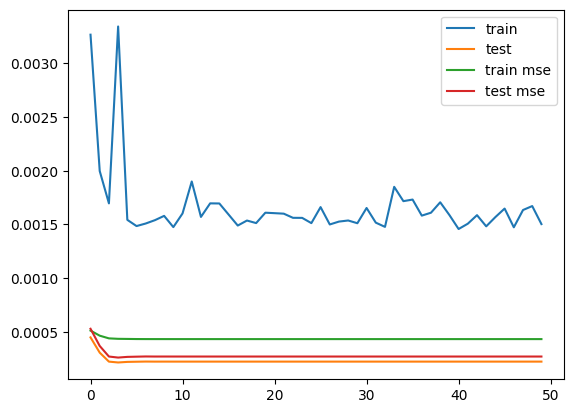

In [16]:
plt.plot(train_losses, label='train')
plt.plot(test_losses, label='test')
plt.plot(e_mses[:, 0], label='train mse')
plt.plot(e_mses[:, 1], label='test mse')
plt.legend()
plt.show()
